# **Generative Adversarial Networks (GANs)**

## **1. What are Generative Models?**

So far, most of the machine learning models discussed have been **discriminative models**.

A discriminative model learns to distinguish between categories or predict an output based on an input.

For example:

- Given an image, predict whether it contains a cat or a dog.
- Given an email, predict whether it is spam or not spam.
- Given a review, predict whether its sentiment is positive or negative.

A generative model learns the underlying patterns and distribution of the training data so that it can generate new, similar data.

For example:

- Generate new human faces.
- Generate synthetic product images.
- Generate handwritten digits.
- Generate realistic artwork.

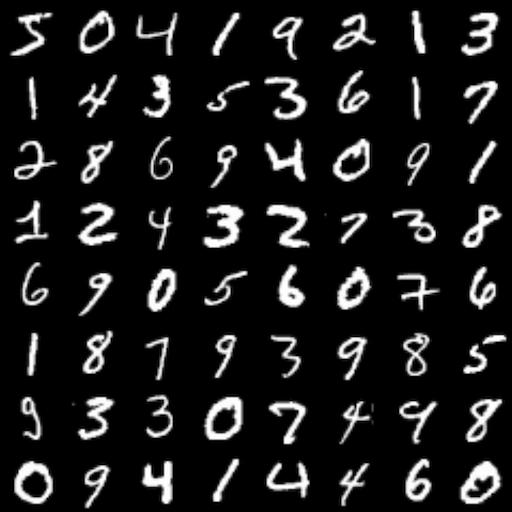

**Real training images**

Examples of handwritten digits used for training.

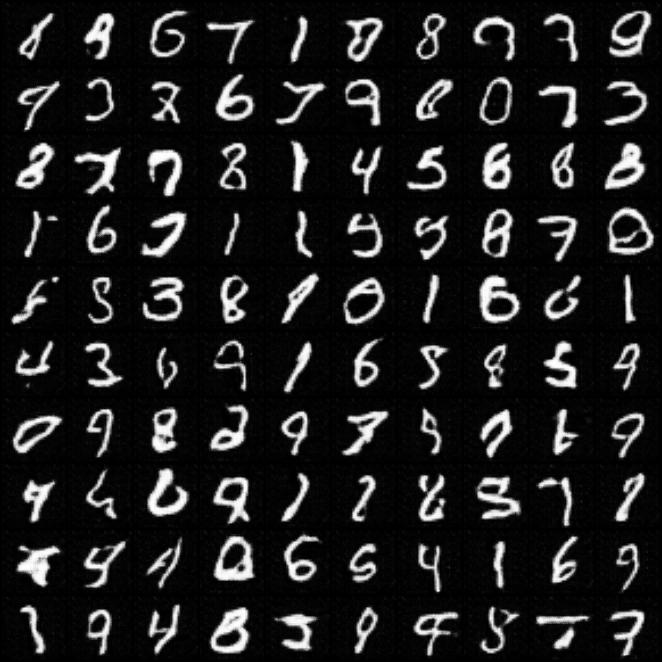

**Generated images**

New digit-like images generated by a trained model.

The important distinction:

| Discriminative model       | Generative model        |
| -------------------------- | ----------------------- |
| Learns to predict labels   | Learns patterns in data |
| Classifies existing inputs | Generates new samples   |
| Example: CNN classifier    | Example: GAN            |

## **2. What is a GAN?**

GAN stands for **Generative Adversarial Network**.

It was introduced by Ian Goodfellow and his colleagues in 2014.

A GAN consists of two neural networks competing against each other:

1. Generator (G)
2. Discriminator (D)

Think of a counterfeiter and a detective.

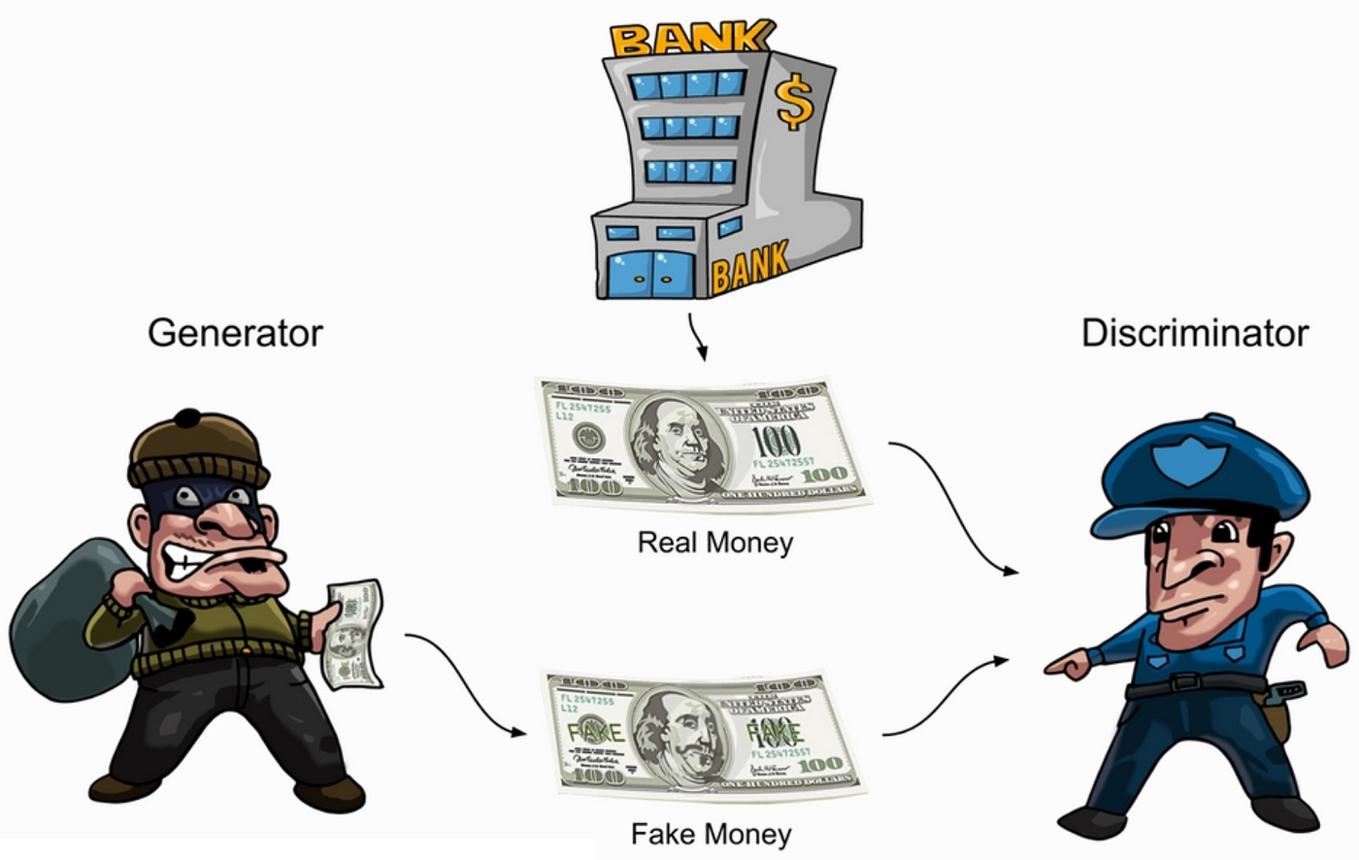

- The Generator creates fake samples.
- The Discriminator examines samples and decides whether they are real or generated.
- The Generator tries to fool the Discriminator.
- The Discriminator tries to identify generated samples correctly.

Both networks improve through this competition.

## **3. Understanding the two networks**

### **A. Generator (G)**

The Generator creates synthetic data.

It starts with random noise and transforms it into an output resembling the training data.

For example, if the training dataset contains handwritten digits, the Generator learns to produce digit-like images.

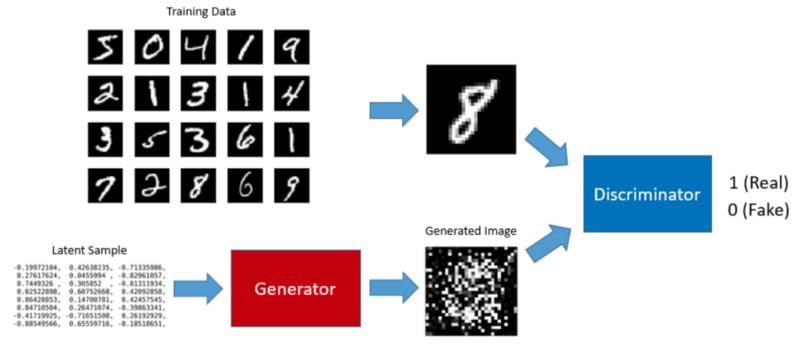

**Input:** Random noise vector.

**Output:** Generated image.

A random noise vector is commonly represented as:

\\[ z \sim \mathcal{N}(0,I) \\]

Where:

- \\(z\\) = random input vector (latent vector)
- \\(\mathcal{N}\\) = normal or Gaussian distribution
- \\(0\\) = mean
- \\(I\\) = identity covariance matrix

For example, the Generator might receive 100 random numbers and produce a 28 × 28 image.

### **B. Discriminator (D)**

The Discriminator acts as a binary classifier.

It receives either:

- A real image from the training dataset.
- A fake image produced by the Generator.

It predicts the probability that the input image is real.

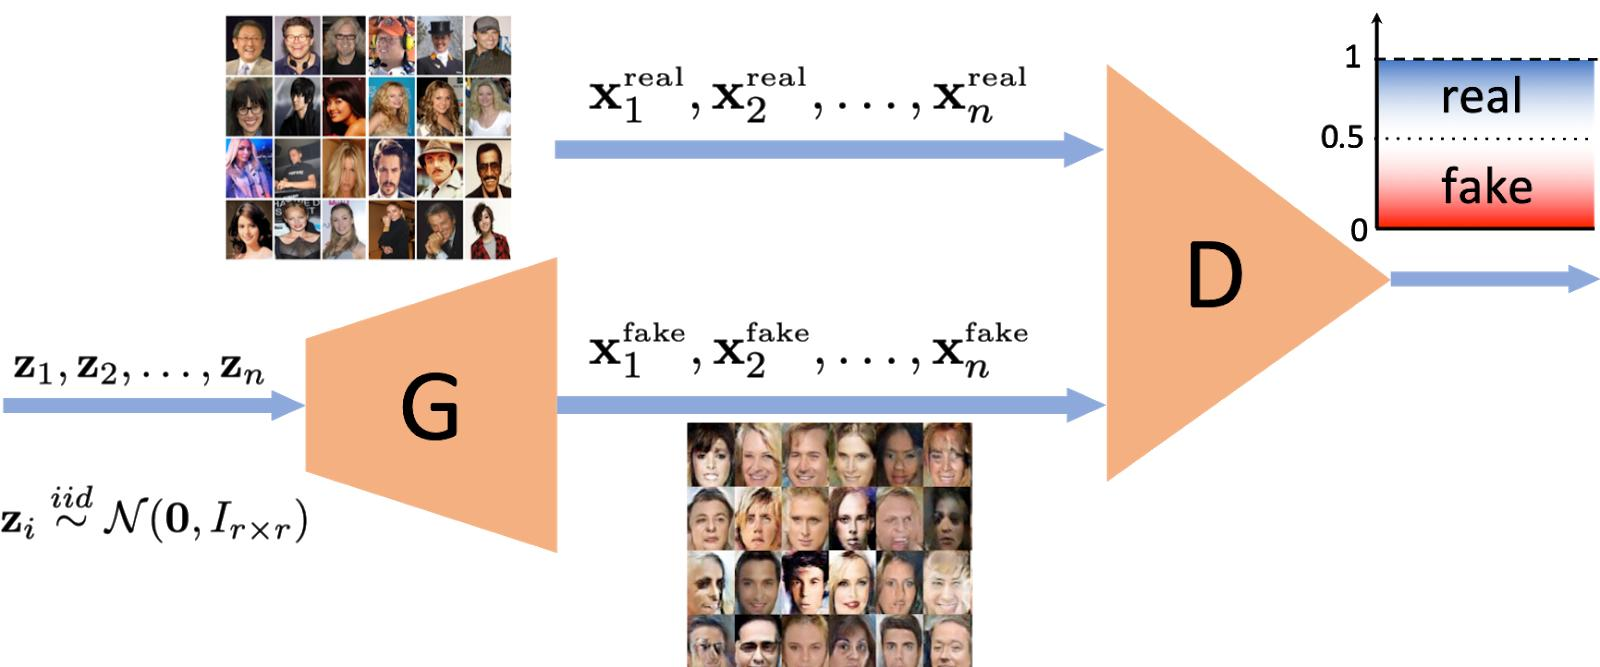

Its output is generally between 0 and 1:

- Close to 1: likely real.
- Close to 0: likely generated.

For example:

| Input                       | Discriminator output |
| --------------------------- | -------------------- |
| Real handwritten digit      | 0.95                 |
| Generated handwritten digit | 0.12                 |

These are illustrative values.

## **4. Complete GAN architecture**

Now connect both networks.

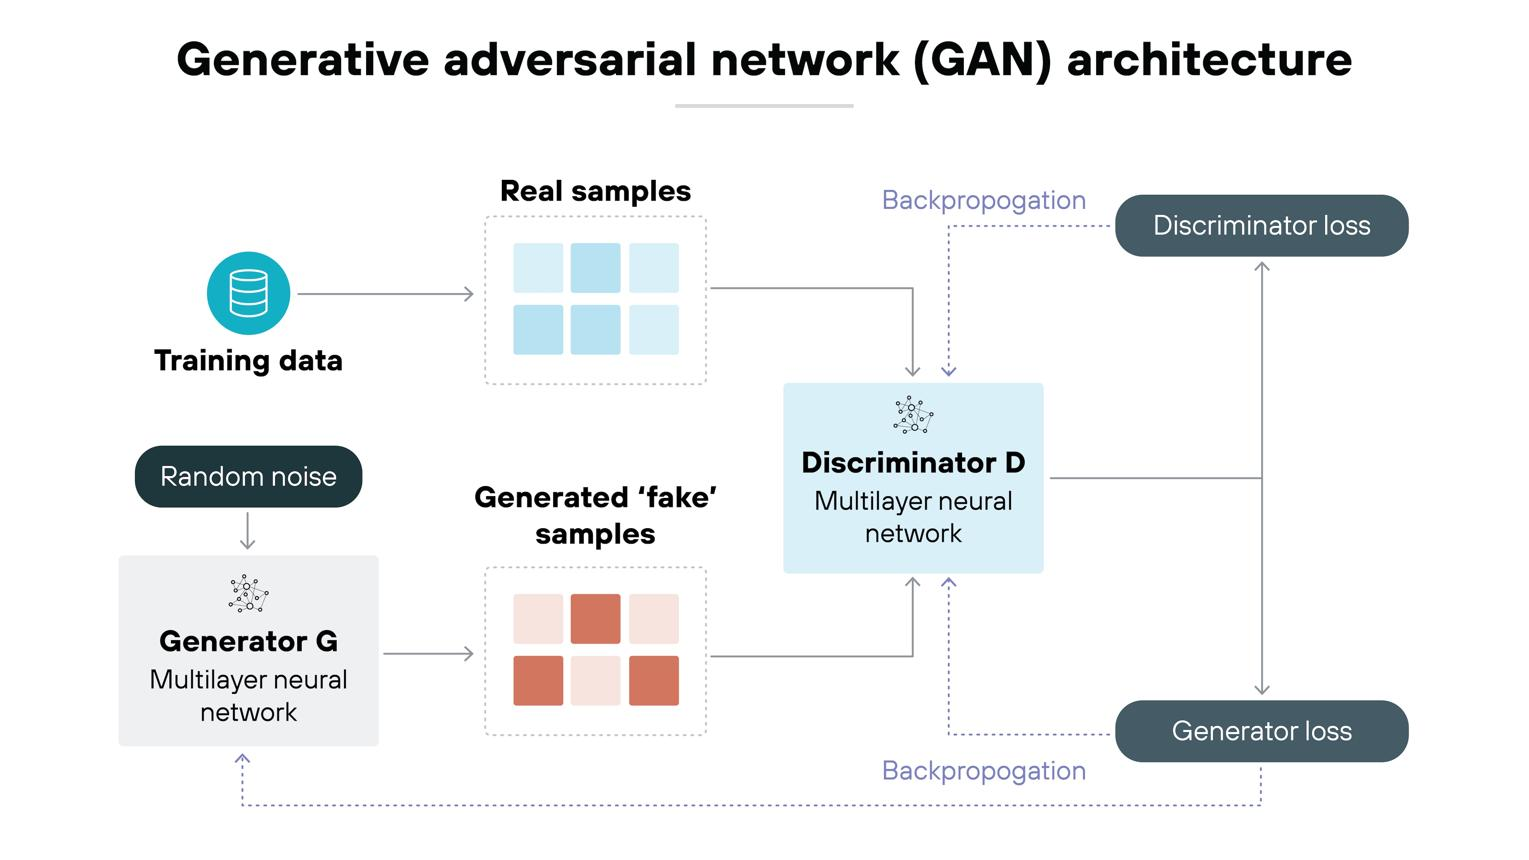

The flow is:

1. Random noise is passed to the Generator.
2. Generator produces a synthetic image.
3. Discriminator receives the generated image.
4. Discriminator also receives real training images.
5. Discriminator predicts whether each image is real or fake.
6. Both networks receive training updates based on their respective objectives.

Notice that the Generator does not directly receive real images as input in a basic GAN. It learns through feedback from the Discriminator.

## **5. How does GAN training work?**

Let's use an example of generating handwritten digits.

**Round 1: Generator produces poor images**

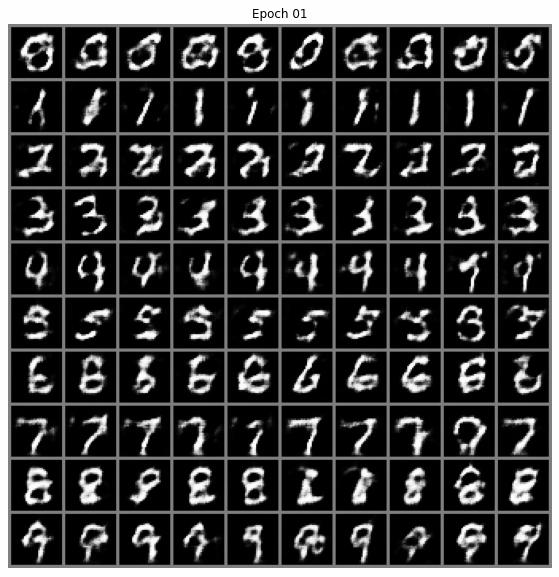

The Discriminator easily identifies them as fake.

**Round 2: Generator improves**

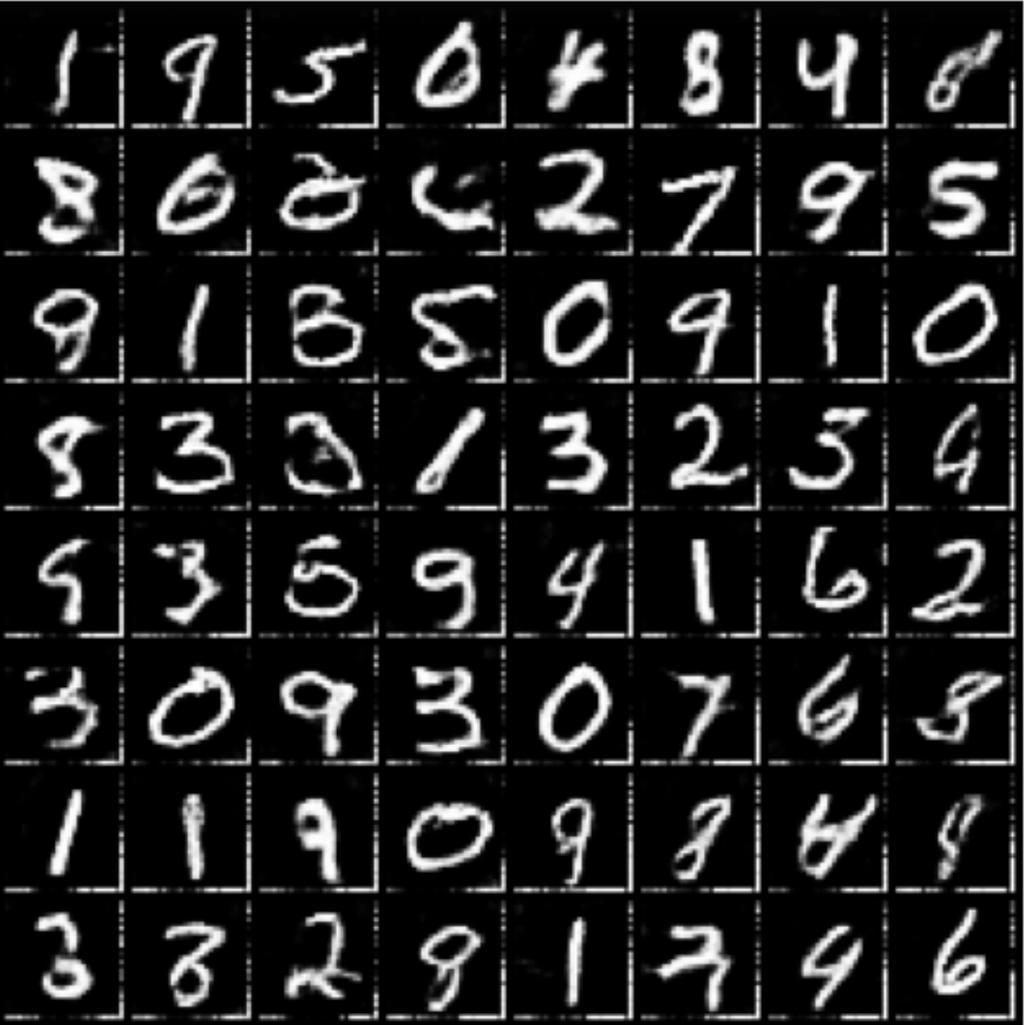

Generated digits start looking more realistic.

**Round 3: Generator becomes better**

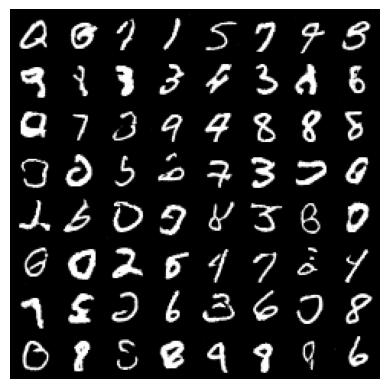

Generated digits resemble real handwritten digits.

The competition continues until the Generator produces samples that the Discriminator struggles to distinguish from real data.

Ideally, the Discriminator's output for real and generated images approaches 0.5.

This is an idealized equilibrium, not a guarantee that every GAN training run reaches it.

## **6. The mathematics behind GANs**

This is the most important mathematical concept.

The original GAN objective is called the **Minimax Objective**.

\\[ \min_G \max_D V(D,G) \\]

Where:

- \\(G\\) = Generator
- \\(D\\) = Discriminator
- \\(\min_G\\) = Generator tries to minimize the objective.
- \\(\max_D\\) = Discriminator tries to maximize the objective.

The objective function is:

\\[ V(D,G) = \mathbb{E}\_{x\sim p\_{data}(x)}[\log D(x)] + \mathbb{E}\_{z\sim p_z(z)}[\log(1-D(G(z)))] \\]

Let's break it down.

**First term:**

\\[ \mathbb{E}\_{x\sim p\_{data}(x)}[\log D(x)] \\]

- \\(x\\) = real training sample.
- \\(p\_{data}(x)\\) = real data distribution.
- \\(D(x)\\) = probability that the Discriminator considers the sample real.
- \\(\log D(x)\\) rewards the Discriminator for identifying real samples correctly.

**Second term:**

\\[ \mathbb{E}\_{z\sim p_z(z)}[\log(1-D(G(z)))] \\]

- \\(z\\) = random noise.
- \\(G(z)\\) = generated sample.
- \\(D(G(z))\\) = probability that the generated sample is considered real.
- \\(1-D(G(z))\\) = probability that it is considered fake.

The Discriminator wants to maximize both terms.

The Generator wants to minimize the second term by producing samples that the Discriminator considers real.

## **7. How are the networks trained?**

The training process alternates between two updates.

**Step 1: Train the Discriminator**

- Take a batch of real images.
- Generate a batch of fake images.
- Label real images as 1 and generated images as 0.
- Calculate Discriminator loss.
- Update Discriminator weights.

**Step 2: Train the Generator**

- Generate another batch of fake images.
- Pass them through the Discriminator.
- Give the Generator's objective a target label of 1 (real).
- Calculate Generator loss.
- Update Generator weights using the feedback.

An important detail: during the Generator update, the Discriminator's weights are frozen, but gradients must still flow through its operations back to the Generator.

## **8. GAN training losses**

The Discriminator has two objectives:

- Correctly identify real images as real.
- Correctly identify generated images as fake.

The Generator has one objective:

\- Make generated images look real to the Discriminator.

In practice, the Generator often uses the non-saturating loss:

\\[ L_G=-\mathbb{E}\_{z}[\log D(G(z))] \\]

The Discriminator loss is:

\\[ L_D=-\mathbb{E}\_{x}[\log D(x)] -\mathbb{E}\_{z}[\log(1-D(G(z)))] \\]

The negative signs convert the maximization objective into minimization losses suitable for gradient descent.

## **9. Common GAN training challenges**

| Challenge                  | Meaning                                                             |
| -------------------------- | ------------------------------------------------------------------- |
| Mode collapse              | Generator produces limited varieties of outputs                     |
| Vanishing gradients        | Generator receives very weak learning signals                       |
| Training instability       | Generator and Discriminator fail to improve consistently            |
| Discriminator overpowering | Discriminator becomes too good, making Generator learning difficult |

For example, mode collapse might cause a GAN trained on handwritten digits to generate mostly the digit 7, even though the training dataset contains digits from 0 to 9.

In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.20.0
Keras: 3.12.0


In [3]:
# Load MNIST dataset
(x_train, _), (_, _) = keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training data shape: (60000, 28, 28)
Minimum pixel value: 0
Maximum pixel value: 255


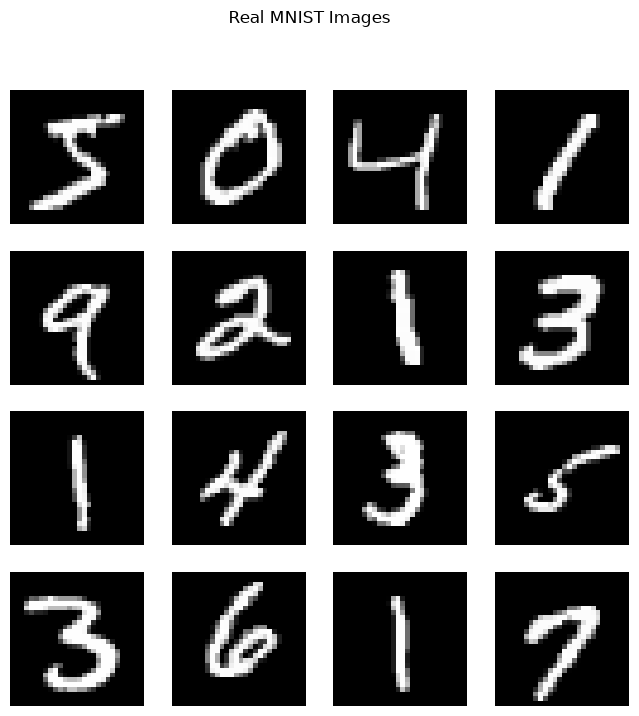

In [4]:
plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Real MNIST Images")
plt.show()

In [5]:
# Add channel dimension: (60000, 28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

# Convert to float32 and normalize
x_train = x_train.astype("float32")

x_train = (x_train - 127.5) / 127.5

print("New shape:", x_train.shape)
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

New shape: (60000, 28, 28, 1)
Minimum: -1.0
Maximum: 1.0


In [6]:
BUFFER_SIZE = 60000
BATCH_SIZE = 128

train_dataset = (
    tf.data.Dataset
    .from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Batches per epoch:", len(train_dataset))

Batches per epoch: 468


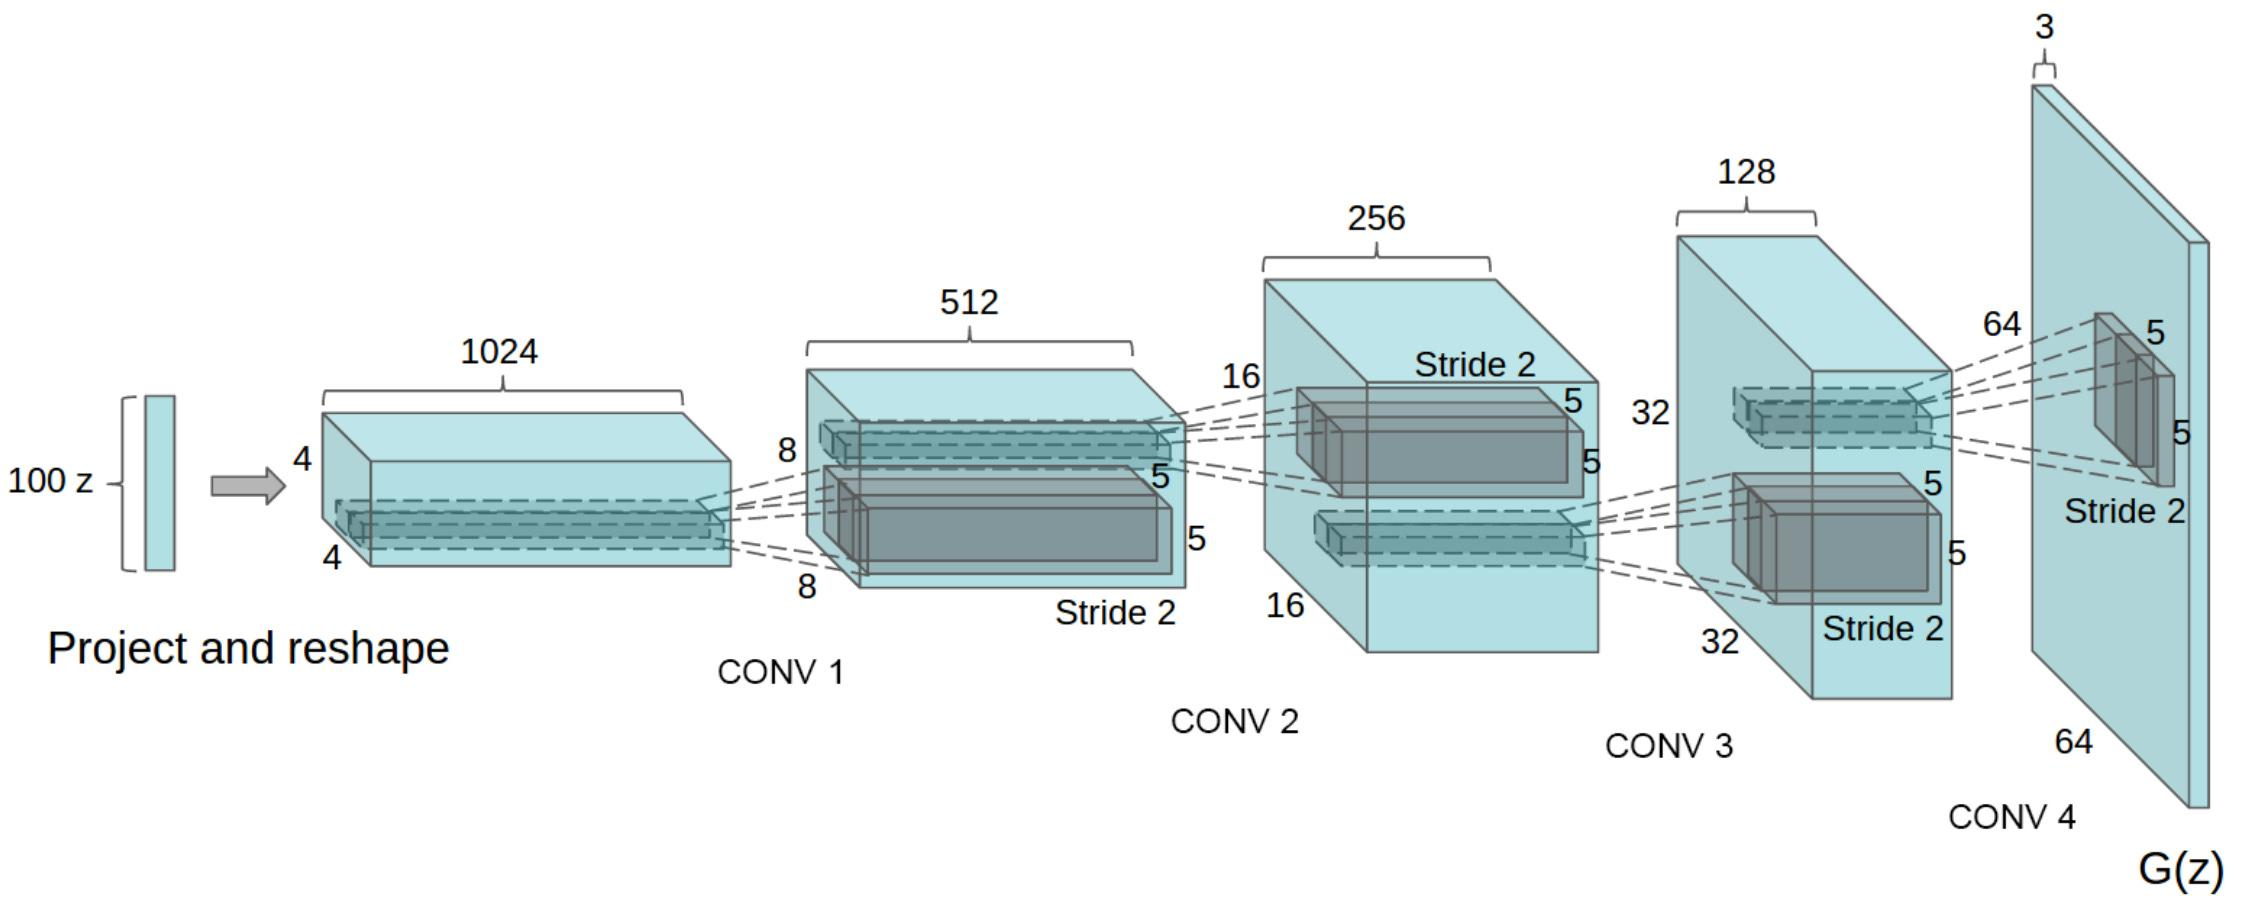

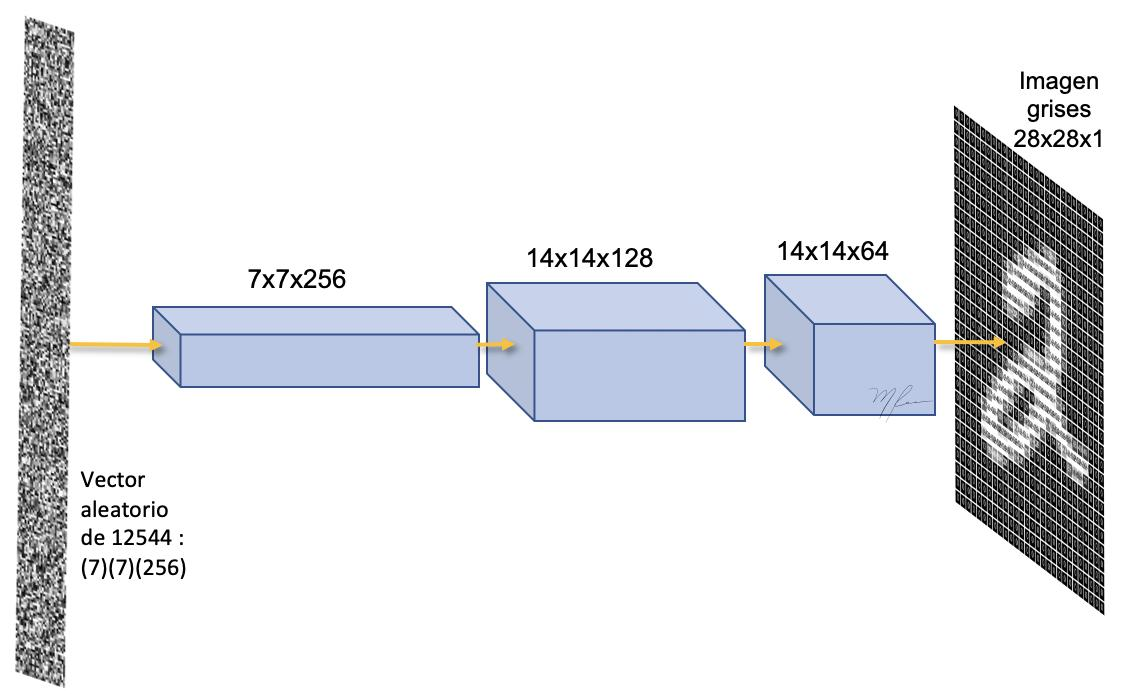

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(2 * 2 * 3),
    layers.Reshape((2, 2, 3))
])

noise = tf.random.normal((1, 4))

output = model(noise)

print(output.shape)

(1, 2, 2, 3)


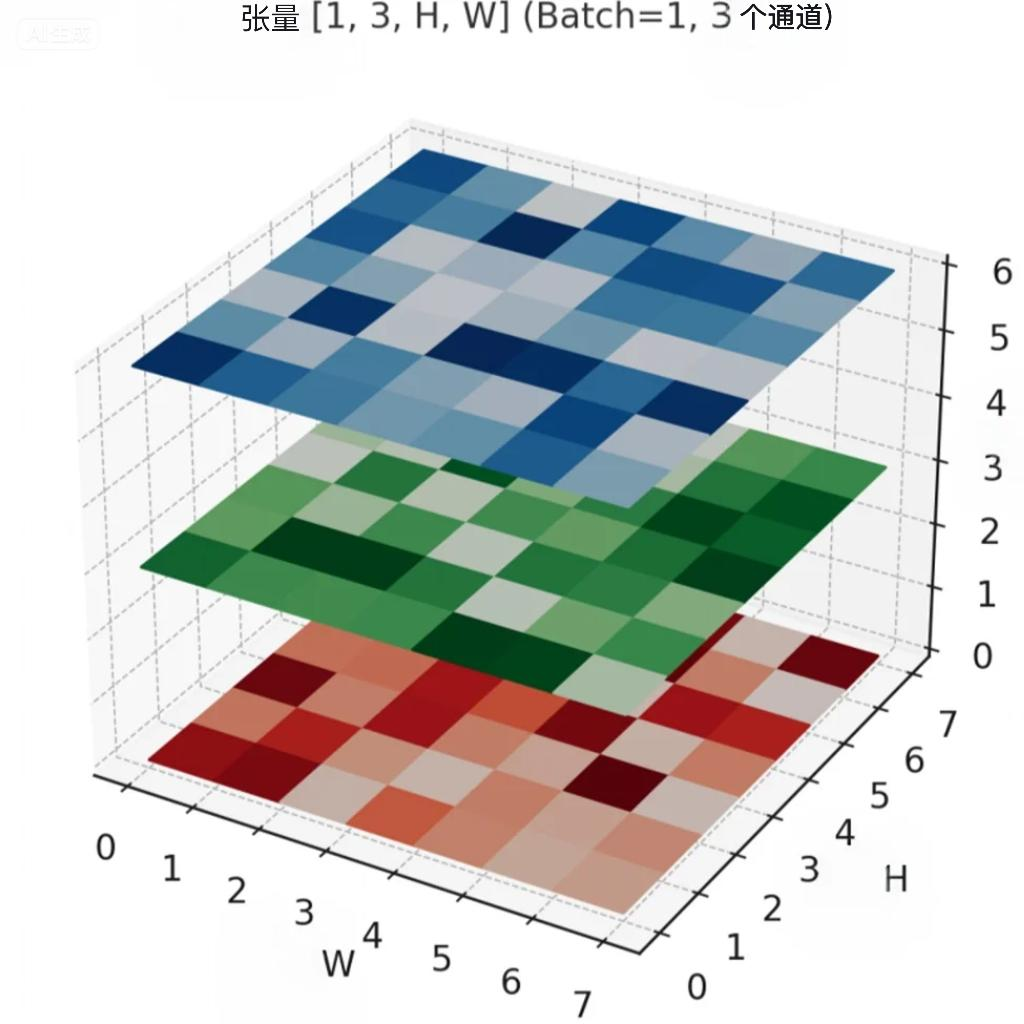

z=[0.23,-0.84,0.56,1.12,.....]
z~N(0,1)

Here:
- (z) is the latent vector.
- (\mathcal{N}\) represents a normal distribution.
- (0) represents the mean.
- (I) represents the identity covariance matrix, giving independent unit-variance components.

In [8]:
LATENT_DIM = 100

generator = keras.Sequential([

    # Input: 100 random numbers
    keras.Input(shape=(LATENT_DIM,)),

    # Expand the random vector
    layers.Dense(7 * 7 * 256, use_bias=False),

    layers.BatchNormalization(),
    layers.LeakyReLU(),

    # Convert vector into a 7x7 feature map
    layers.Reshape((7, 7, 256)),

    # 7x7 -> 7x7
    layers.Conv2DTranspose(
        128,
        kernel_size=5,
        strides=1,
        padding="same",
        use_bias=False
    ),

    layers.BatchNormalization(),
    layers.LeakyReLU(),

    # 7x7 -> 14x14
    layers.Conv2DTranspose(
        64,
        kernel_size=5,
        strides=2,
        padding="same",
        use_bias=False
    ),

    layers.BatchNormalization(),
    layers.LeakyReLU(),

    # 14x14 -> 28x28
    layers.Conv2DTranspose(
        1,
        kernel_size=5,
        strides=2,
        padding="same",
        activation="tanh"
    )

], name="Generator")

generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 12544)               │       1,254,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 12544)               │          50,176 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu (LeakyReLU)              │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_2 (Reshape)                  │ (None, 7, 7, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)   │ (None, 7, 7, 128)           │         819,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 7, 7, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_1 (LeakyReLU)            │ (None, 7, 7, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose) │ (None, 14, 14, 64)          │         204,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_2 (Conv2DTranspose) │ (None, 28, 28, 1)           │           1,601 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [9]:
# Generate 5 random noise vectors
noise = tf.random.normal((5, LATENT_DIM))

# Generate images
generated_images = generator(noise, training=False)

print("Generated image shape:", generated_images.shape)

Generated image shape: (5, 28, 28, 1)


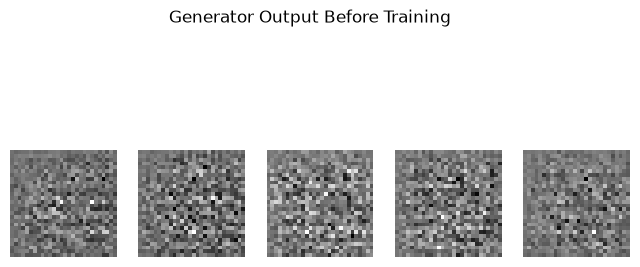

In [10]:
plt.figure(figsize=(8, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("Generator Output Before Training")
plt.show()

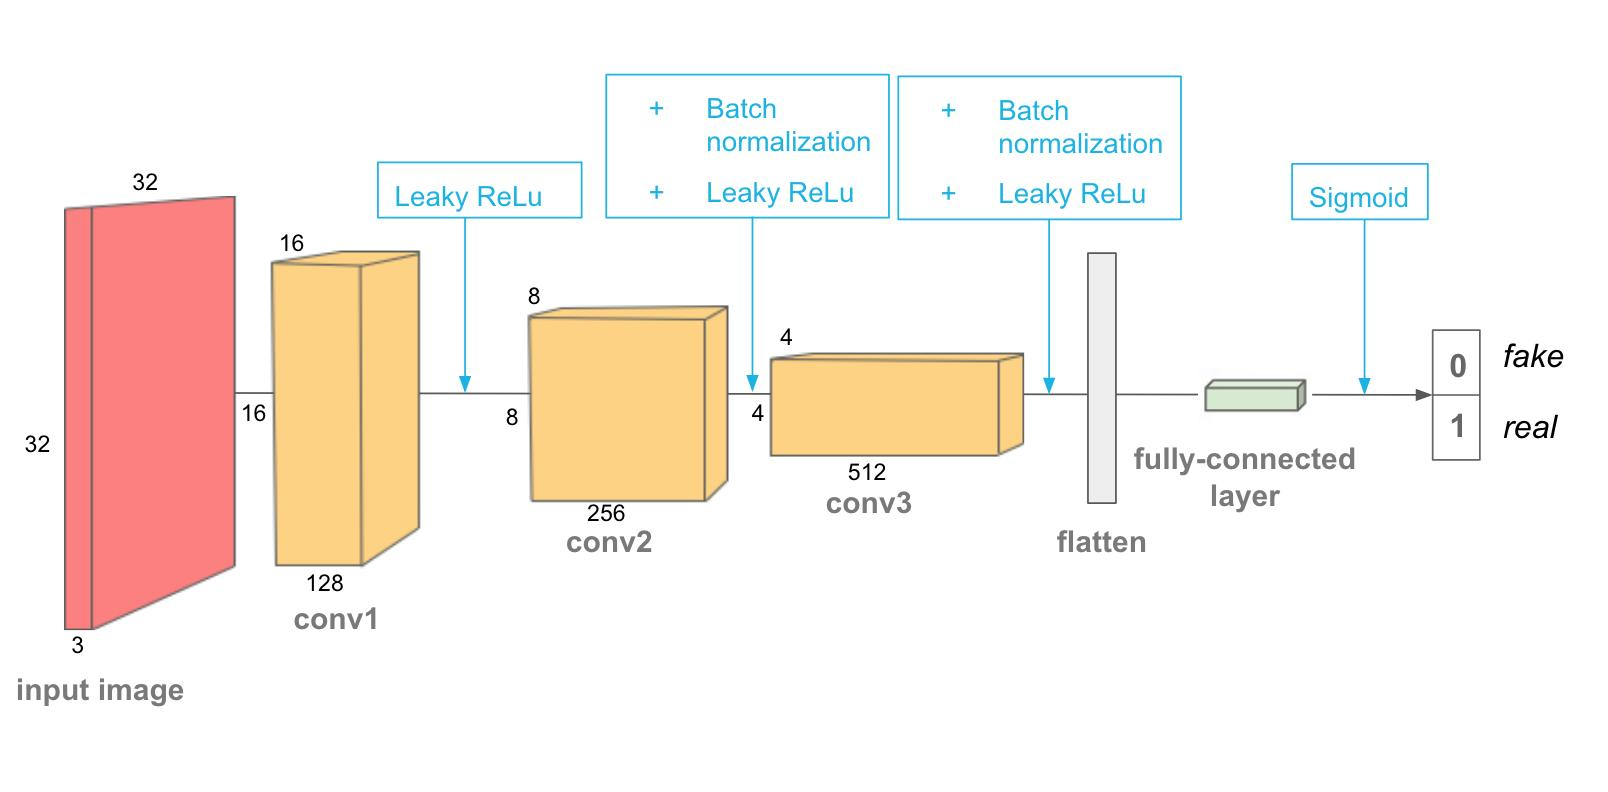

In [11]:
discriminator = keras.Sequential([

    keras.Input(shape=(28, 28, 1)),

    # First convolutional block
    layers.Conv2D(
        64,
        kernel_size=5,
        strides=2,
        padding="same"
    ),

    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    # Second convolutional block
    layers.Conv2D(
        128,
        kernel_size=5,
        strides=2,
        padding="same"
    ),

    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    # Flatten feature maps
    layers.Flatten(),

    # One output logit
    layers.Dense(1)

], name="Discriminator")

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 14, 14, 64)          │           1,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 7, 7, 128)           │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_4 (LeakyReLU)            │ (None, 7, 7, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 7, 7, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │           6,273 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Test using real images
real_images = tf.convert_to_tensor(x_train[:5])

predictions = discriminator(
    real_images,
    training=False
)

print("Discriminator output shape:", predictions.shape)
print(predictions.numpy())

Discriminator output shape: (5, 1)
[[-0.06690775]
 [-0.13055992]
 [-0.09052987]
 [-0.16294973]
 [-0.07549281]]


In [13]:
cross_entropy = keras.losses.BinaryCrossentropy(
    from_logits=True
)

def discriminator_loss(real_output, fake_output):

    # Real images should be classified as 1
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    # Generated images should be classified as 0
    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss


def generator_loss(fake_output):

    # Generator wants fake images to be classified as real
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [14]:
generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5
)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5
)

In [ ]:
# Example
import tensorflow as tf

x = tf.Variable(3.0)

with tf.GradientTape() as tape:

    y = x ** 2

gradient = tape.gradient(y, x)

print("Value:", y.numpy())
print("Gradient:", gradient.numpy())

In [ ]:
# Example 

model = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(1)
])

optimizer = keras.optimizers.SGD(learning_rate=0.01)
loss_function = keras.losses.MeanSquaredError()

x = tf.constant([[2.0]])
y_actual = tf.constant([[10.0]])

with tf.GradientTape() as tape:

    y_predicted = model(x)

    loss = loss_function(y_actual, y_predicted)

gradients = tape.gradient(
    loss,
    model.trainable_variables
)

print("Prediction:", y_predicted.numpy())
print("Loss:", loss.numpy())

for gradient in gradients:
    print("Gradient:", gradient.numpy())

In [ ]:
# Updating the weights
optimizer.apply_gradients(
    zip(gradients, model.trainable_variables)
)

In [ ]:
# inpect the updated parameters
for variable in model.trainable_variables:
    print(variable.numpy())

1. Discriminator training
During Discriminator training:
- Pass real images through the Discriminator.
- Generate fake images using the Generator.
- Pass fake images through the Discriminator.
- Calculate Discriminator loss.
- Calculate gradients with respect to Discriminator weights.
- Update only Discriminator weights.
2. Generator training
During Generator training:
- Generate images using random noise.
- Pass generated images through the Discriminator.
- Calculate Generator loss.
- Calculate gradients with respect to Generator weights.
- Update only Generator weights.

In [16]:
@tf.function
def train_discriminator(real_images):

    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal(
        [batch_size, LATENT_DIM]
    )

    # Generate fake images
    generated_images = generator(
        noise,
        training=True
    )

    # Do not propagate this update into Generator
    generated_images = tf.stop_gradient(generated_images)

    with tf.GradientTape() as disc_tape:

        # Predictions for real images
        real_output = discriminator(
            real_images,
            training=True
        )

        # Predictions for generated images
        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Calculate Discriminator loss
        d_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients only for Discriminator weights
    gradients = disc_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    # Update Discriminator weights
    discriminator_optimizer.apply_gradients(
        zip(
            gradients,
            discriminator.trainable_variables
        )
    )

    return d_loss

In [17]:
@tf.function
def train_generator(batch_size):

    # Generate random noise
    noise = tf.random.normal(
        [batch_size, LATENT_DIM]
    )

    with tf.GradientTape() as gen_tape:

        # Generate fake images
        generated_images = generator(
            noise,
            training=True
        )

        # Ask Discriminator to evaluate generated images
        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Generator wants Discriminator to predict real (1)
        g_loss = generator_loss(fake_output)

    # Calculate gradients only for Generator weights
    gradients = gen_tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    # Update Generator weights
    generator_optimizer.apply_gradients(
        zip(
            gradients,
            generator.trainable_variables
        )
    )

    return g_loss

In [18]:
EPOCHS = 20

# Fixed random noise to monitor Generator progress
NUM_EXAMPLES = 16

seed = tf.random.normal(
    [NUM_EXAMPLES, LATENT_DIM]
)

def train_gan(dataset, epochs):

    for epoch in range(epochs):

        generator_loss_metric = keras.metrics.Mean()
        discriminator_loss_metric = keras.metrics.Mean()

        for image_batch in dataset:

            # Step 1: Train Discriminator
            d_loss = train_discriminator(image_batch)

            # Step 2: Train Generator
            g_loss = train_generator(
                tf.shape(image_batch)[0]
            )

            generator_loss_metric.update_state(g_loss)
            discriminator_loss_metric.update_state(d_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"D Loss: {discriminator_loss_metric.result():.4f} | "
            f"G Loss: {generator_loss_metric.result():.4f}"
        )

        # Generate images after every epoch
        predictions = generator(seed, training=False)

        if (epoch + 1) % 5 == 0:
            generate_and_save_images(
                generator,
                epoch + 1,
                seed
            )

In [19]:
def generate_and_save_images(model, epoch, test_input):

    predictions = model(
        test_input,
        training=False
    )

    # Convert pixel range from [-1, 1] to [0, 1]
    predictions = (predictions + 1) / 2

    plt.figure(figsize=(6, 6))

    for i in range(16):

        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap="gray"
        )

        plt.axis("off")

    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.show()

Epoch 1/20 | D Loss: 1.2944 | G Loss: 0.7011
Epoch 2/20 | D Loss: 1.3182 | G Loss: 0.7715
Epoch 3/20 | D Loss: 1.2875 | G Loss: 0.8043
Epoch 4/20 | D Loss: 1.3215 | G Loss: 0.7702
Epoch 5/20 | D Loss: 1.3375 | G Loss: 0.7497


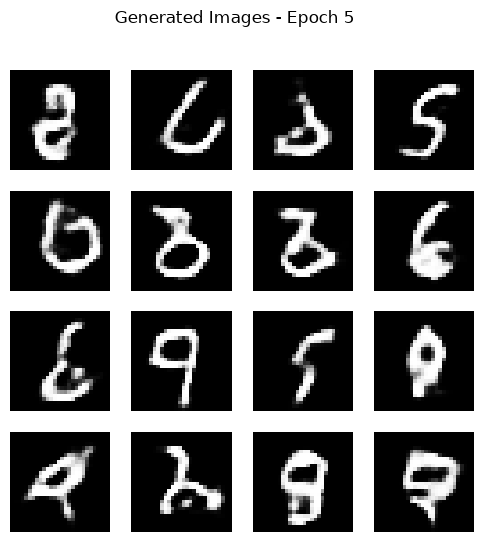

Epoch 6/20 | D Loss: 1.3394 | G Loss: 0.7490
Epoch 7/20 | D Loss: 1.3378 | G Loss: 0.7647
Epoch 8/20 | D Loss: 1.3308 | G Loss: 0.7623
Epoch 9/20 | D Loss: 1.3270 | G Loss: 0.7749
Epoch 10/20 | D Loss: 1.3179 | G Loss: 0.7736


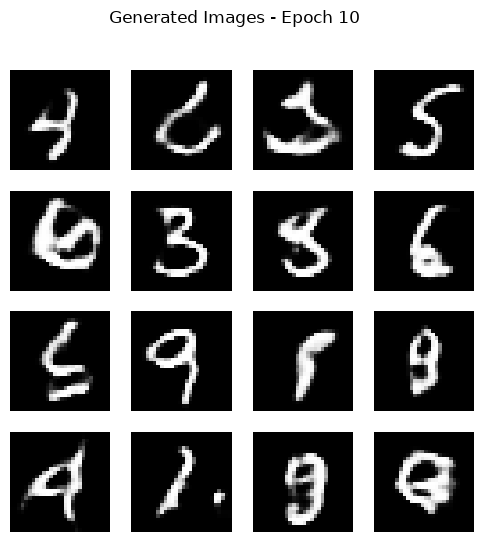

Epoch 11/20 | D Loss: 1.3142 | G Loss: 0.7789
Epoch 12/20 | D Loss: 1.3130 | G Loss: 0.7908
Epoch 13/20 | D Loss: 1.3091 | G Loss: 0.7935
Epoch 14/20 | D Loss: 1.3029 | G Loss: 0.7974
Epoch 15/20 | D Loss: 1.3003 | G Loss: 0.7959


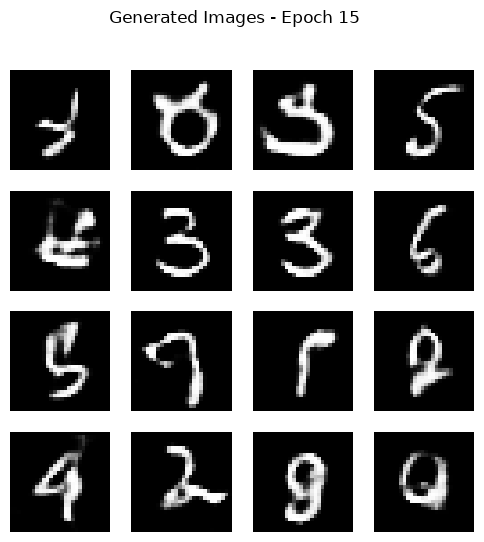

Epoch 16/20 | D Loss: 1.3002 | G Loss: 0.8124
Epoch 17/20 | D Loss: 1.2960 | G Loss: 0.8036
Epoch 18/20 | D Loss: 1.2986 | G Loss: 0.8117
Epoch 19/20 | D Loss: 1.2996 | G Loss: 0.8221
Epoch 20/20 | D Loss: 1.2960 | G Loss: 0.8053


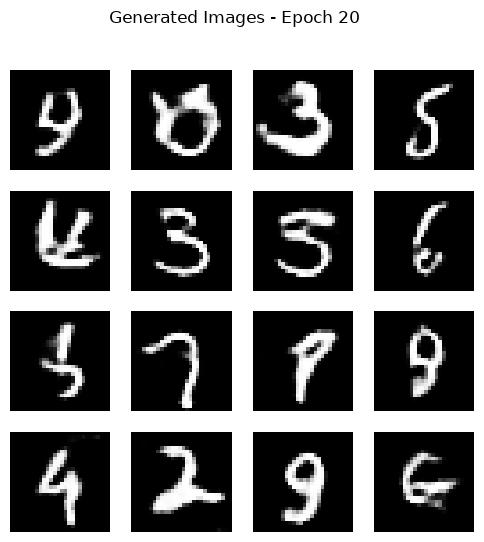

In [20]:
train_gan(
    train_dataset,
    EPOCHS
)

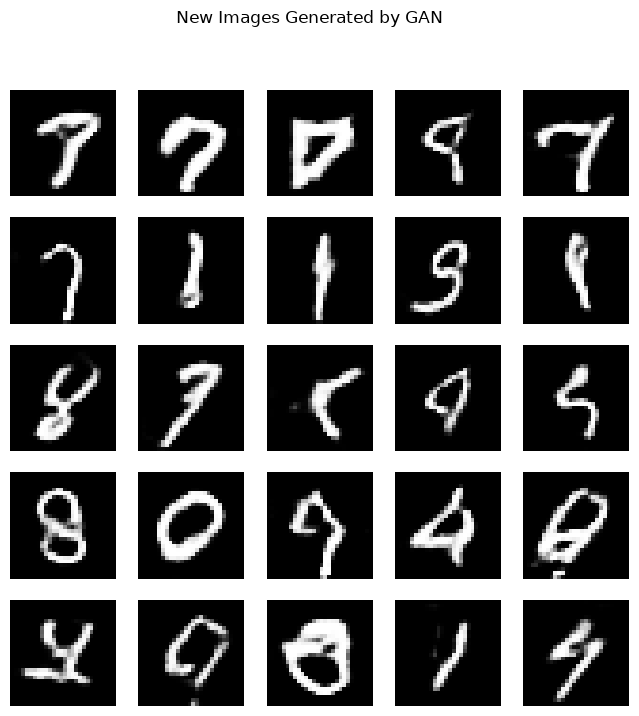

In [21]:
# Generate 25 new random noise vectors
new_noise = tf.random.normal(
    [25, LATENT_DIM]
)

# Generate new images
new_images = generator(
    new_noise,
    training=False
)

# Convert to display range
new_images = (new_images + 1) / 2

plt.figure(figsize=(8, 8))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.imshow(
        new_images[i, :, :, 0],
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("New Images Generated by GAN")
plt.show()

In [22]:
generator.save("mnist_gan_generator.keras")

In [23]:
loaded_generator = keras.models.load_model(
    "mnist_gan_generator.keras"
)

noise = tf.random.normal([5, LATENT_DIM])

generated = loaded_generator(
    noise,
    training=False
)

print(generated.shape)

(5, 28, 28, 1)
